In [1]:
import pandas as pd

In [2]:
# filepath_or_buffer
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"

In [3]:
df = pd.read_csv(url) # buffer

In [4]:
df.tail(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [5]:
del df["PassengerId"]
del df["Ticket"]
del df["Cabin"]

In [6]:
df.tail(5)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
886,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,13.00,S
887,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,30.00,S
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,23.45,S
889,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,30.00,C
890,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,7.75,Q


In [7]:
import re
title = []
for row in df["Name"]:
    pattern = r", ([A-Za-z ]+\.).*"
    title.append(re.search(pattern, row).group(1))

In [8]:
df["Title"] = title

In [9]:
del df["Name"]

In [10]:
df.tail(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
886,0,2,male,27.0,0,0,13.00,S,Rev.
887,1,1,female,19.0,0,0,30.00,S,Miss.
888,0,3,female,NaN,1,2,23.45,S,Miss.
889,1,1,male,26.0,0,0,30.00,C,Mr.
890,0,3,male,32.0,0,0,7.75,Q,Mr.


In [11]:
X = df.drop("Survived", axis = 1)
y = df["Survived"]

# Separar variables

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
# Separar conjuntos de datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify = y, random_state=20261019
)

In [14]:
X_train = X_train.reset_index(drop = True)
X_test = X_test.reset_index(drop = True)

In [15]:
X_train["Age"].mean()

np.float64(29.843047034764826)

In [16]:
# Imputación de variables
age_mean_pob = X_train["Age"].mean()
X_train["Age"] = X_train["Age"].fillna(age_mean_pob)
X_test["Age"] = X_test["Age"].fillna(age_mean_pob)

In [17]:
moda_embarked_pob = X_train["Embarked"].mode().iloc[0]
X_train["Embarked"] = X_train["Embarked"].fillna(moda_embarked_pob)
X_test["Embarked"] = X_test["Embarked"].fillna(moda_embarked_pob)

In [18]:
# Crear variables
X_train["Family_size"] = X_train["SibSp"] + X_train["Parch"] + 1
X_test["Family_size"] = X_test["SibSp"] + X_test["Parch"] + 1

X_train["Alone"] = X_train["Family_size"] == 1
X_test["Alone"] = X_test["Family_size"] == 1


X_train["Free_ticket"] = X_train["Fare"] == 0.0
X_test["Free_ticket"] = X_test["Fare"] == 0.0

In [19]:
from sklearn.preprocessing import OneHotEncoder

In [20]:
for column in ["Title", "Pclass", "Embarked", "Sex"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown = "ignore")
    encoder.fit(X_train[[column]])
    X_train = pd.concat([
        X_train.drop(column, axis = 1),
        pd.DataFrame(
            encoder.transform(X_train[[column]]),
            columns = map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis = 1
    )
    X_test = pd.concat([
        X_test.drop(column, axis = 1),
        pd.DataFrame(
            encoder.transform(X_test[[column]]),
            columns = map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis = 1
    )

In [21]:
from sklearn.preprocessing import RobustScaler
for numeric_column in ["Age", "SibSp", "Parch", "Fare", "Family_size"]:
    scaler = RobustScaler()
    scaler.fit(X_train[[numeric_column]])
    X_train[numeric_column] = scaler.transform(X_train[[numeric_column]])
    X_test[numeric_column] = scaler.transform(X_test[[numeric_column]])

In [22]:
X_train.shape

(623, 28)

In [23]:
X_test.shape

(268, 28)

In [24]:
import tensorflow as tf
tf.keras.utils.set_random_seed(20261019)

In [25]:
# 1. Diseñar la red neuronal
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])

In [26]:
# 2. Configurar la red neuronal
model.compile(
    loss = "binary_crossentropy",
    optimizer = tf.keras.optimizers.SGD(learning_rate = 0.1),
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [27]:
# 3. Entrenar modelo
model.fit(X_train, y_train, epochs = 1000, verbose = 0)

In [28]:
# 4. Predecir
y_pred = model.predict(X_test, verbose = 0) > 0.5

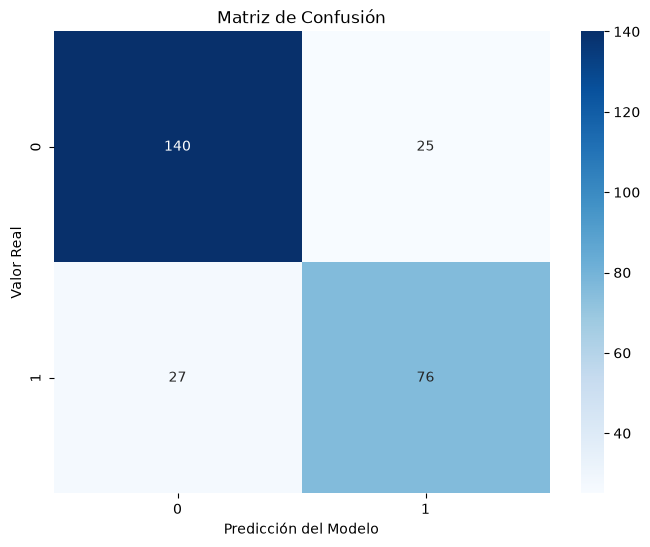

In [29]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()